# Modeling results

In [14]:
# Automatic module reloading
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Add project root
PROJ_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJ_ROOT))

# Notebooks imports
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 0. Load results

In [15]:
# Pooled prediction csvs
xgb_random = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_xgb_grouped/predictions.csv")
xgb_grouped = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_xgb_grouped/predictions.csv")
xgb_loso = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_xgb_loso/predictions.csv")
xgb_lomo = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_xgb_lomo/predictions.csv")

# Metrics jsons
xgb_random_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_xgb_grouped/metrics.json"))
xgb_grouped_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_xgb_grouped/metrics.json"))
xgb_loso_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_xgb_loso/metrics.json"))
xgb_lomo_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_xgb_lomo/metrics.json"))


## 1. Predictions scatter

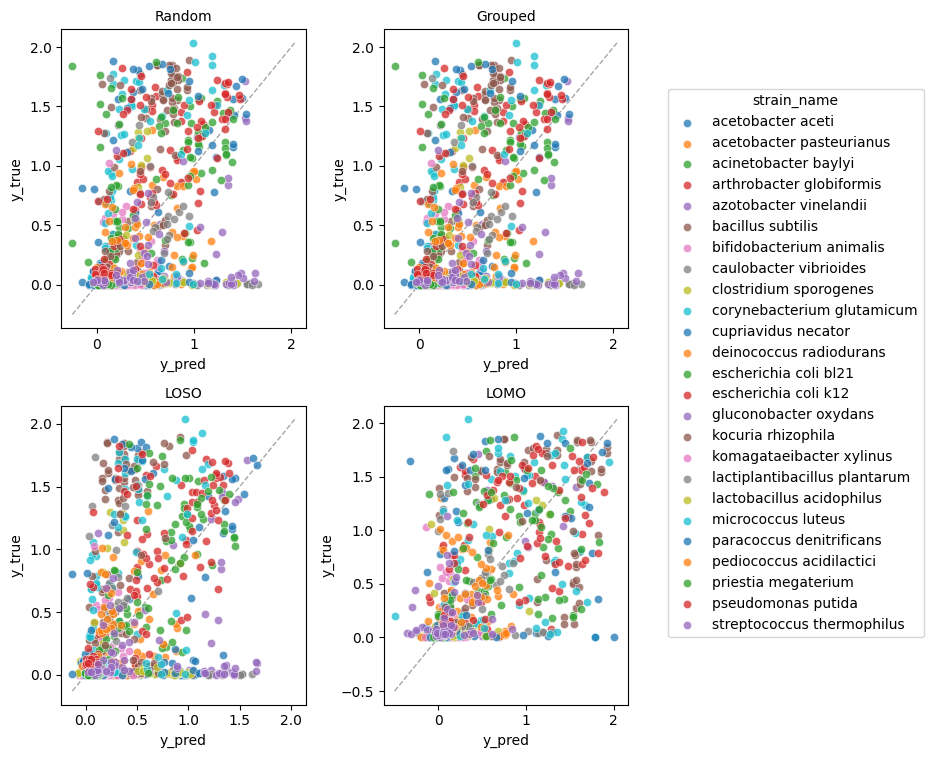

In [16]:
from src.modeling.plots import plot_scatter_predictions

fig = plot_scatter_predictions([xgb_random, xgb_grouped, xgb_loso, xgb_lomo], 
                               titles=["Random", "Grouped", "LOSO", "LOMO"], 
                               color_by="strain_name")

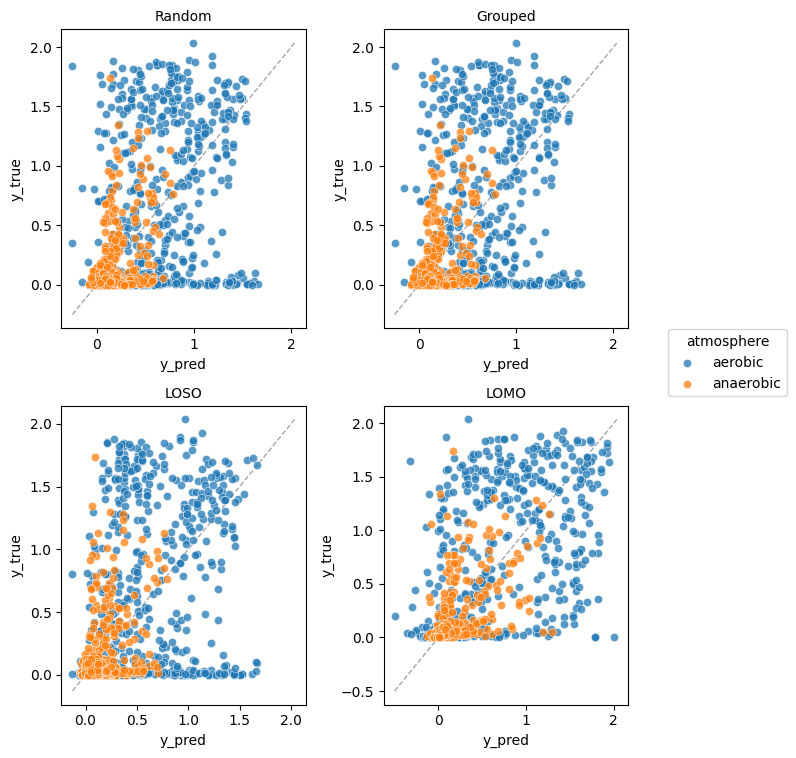

In [17]:
from src.modeling.plots import plot_scatter_predictions

fig = plot_scatter_predictions([xgb_random, xgb_grouped, xgb_loso, xgb_lomo], 
                               titles=["Random", "Grouped", "LOSO", "LOMO"], 
                               color_by="atmosphere")

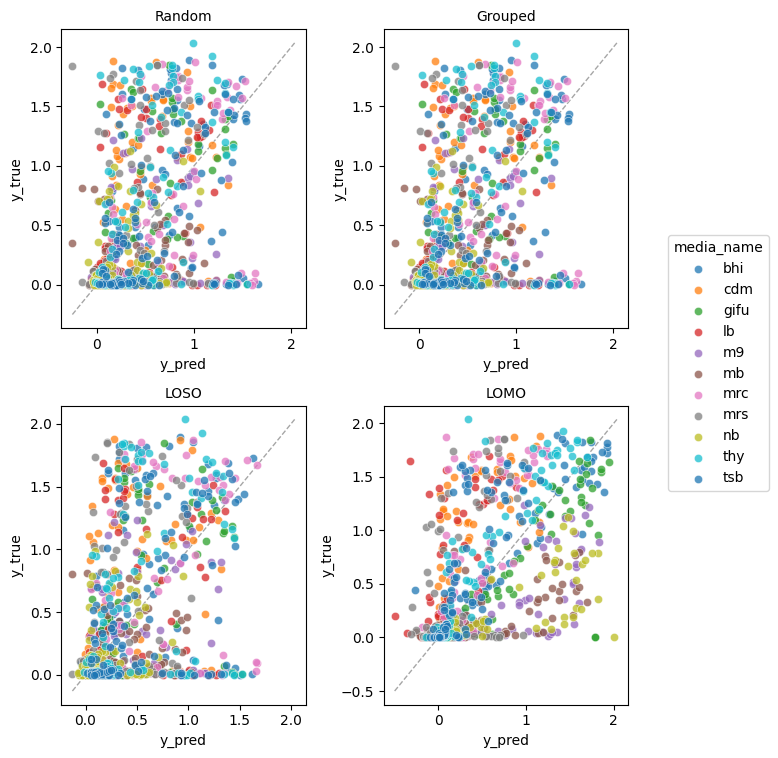

In [18]:
from src.modeling.plots import plot_scatter_predictions

fig = plot_scatter_predictions([xgb_random, xgb_grouped, xgb_loso, xgb_lomo], 
                               titles=["Random", "Grouped", "LOSO", "LOMO"], 
                               color_by="media_name")

## 2. Metrics comparison

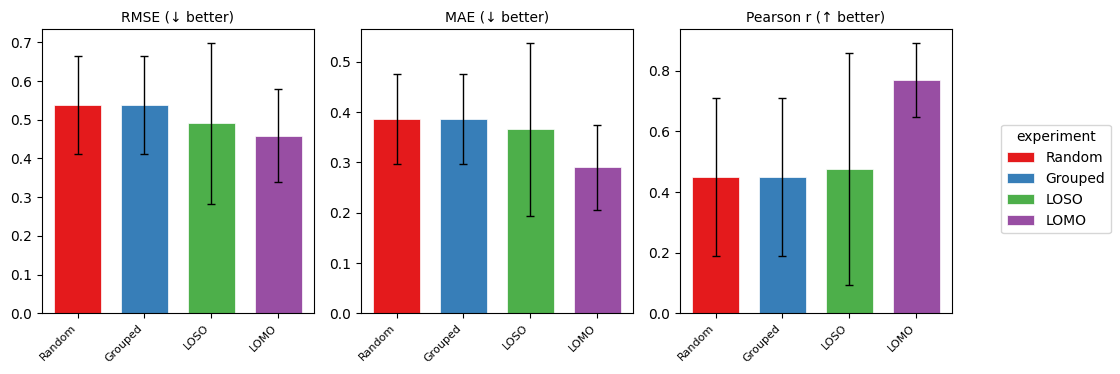

In [22]:
from src.modeling.plots import plot_metrics_comparison

fig = plot_metrics_comparison([xgb_random_metrics, xgb_grouped_metrics, xgb_loso_metrics, xgb_lomo_metrics], 
                              metrics=["rmse", "mae", "pearson_r"],
                              metric_titles=["RMSE (↓ better)", "MAE (↓ better)", "Pearson r (↑ better)"],
                              json_titles=["Random", "Grouped", "LOSO", "LOMO"])
